# Türkçe Film Yorumlarında Duygu Analizi

**Doğal Dil İşleme Dersi — Proje**  
**Konu:** Counting Vectors ve TF-IDF ile metin vektörleştirme, Karar Ağacı ile olumlu/olumsuz sınıflandırma  
**Ortam:** Python / Jupyter Notebook  

## Projenin Amacı

Bu çalışmada Türkçe film yorumları **olumlu (1)** ve **olumsuz (0)** sınıflarına ayrılır. Proje, derste geçen **tokenization, stop words, Counting Vectors, TF-IDF, denetimli öğrenme, Decision Tree, accuracy/precision/recall/F1, confusion matrix, N-Fold Cross Validation ve Grid Search** konularına dayanır.

> **Bilimsel dürüstlük / veri kaynağı:** `film_yorumlari.csv` tamamen bu proje için yazılmış cümle havuzlarından, `veri_seti_olustur.py` koduyla üretilmiş **1.000 sentetik yorum** içerir; bunlar gerçek film izleyicilerinin yorumları değildir. Cümlelerin bazıları aynı temel metnin varyasyonudur. `temel_id` sayesinde aynı kök cümle eğitim ve test kümelerine birlikte girmez. Ayrı bir `zor_ornekler.csv` dosyasındaki **40 ayrıca tasarlanmış zor örnek**, modelin sınırlılıklarını görmeye yarar. Bu veriler **gerçek dünya başarısı kanıtı değildir**. Aşağıdaki bütün sonuçlar Notebook çalıştırılarak hesaplanır.


## 1. Ortamın hazırlanması

Bu hücre notebook'u çalıştırmak için gereken paketleri ve tekrar üretilebilirlik için kullanılan rastgelelik tohumunu gösterir. CSV dosyaları notebook ile aynı klasörde bulunmalıdır.

In [43]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
SONUCLAR = BASE_DIR / "sonuclar"
SONUCLAR.mkdir(exist_ok=True)
print("Python/Scikit-learn:", sklearn.__version__)
print("Çalışma dizini:", BASE_DIR)
print("Dosyalar mevcut:", (BASE_DIR / "film_yorumlari.csv").exists(),
      (BASE_DIR / "zor_ornekler.csv").exists())

Python/Scikit-learn: 1.9.1
Çalışma dizini: c:\Users\mert_\Desktop\film_yorumlari_duygu_analizi
Dosyalar mevcut: True True


## 2. Veri setini okuma ve keşfetme

**Etiketler:** `1 = olumlu`, `0 = olumsuz`.  
`temel_id`, aynı çekirdek yorumun varyasyonlarını gruplayan bir kimliktir; **metin sınıflandırıcısına özellik olarak verilmez**. Böylece model yapay `temel_id` sütununa bakarak etiket tahmini yapamaz.

Veri kümesi: (1000, 3) | Bağımsız zor örnek: (40, 2)
Sınıf dağılımı: {0: 500, 1: 500}
Temel yorum grubu sayısı: 160


,yorum,etiket
0,Bu filmi arkadaşlarıma gönül rahatlığıyla öner...,1
1,"Yeni keşfettiğim bu filmde, film çok iyi bir t...",1
2,"Sinemadan çıktıktan sonra düşündüm ki, karmaşı...",1
3,Ayrıntıların çoğunun bir amacı yoktu. Yapım ha...,0
4,"Bugün izlediğim filmde, hikâyedeki dönüşüm çok...",1
5,"İlk defa izlediğim yapımda, dram ve mizah aras...",1
6,"Rastgele seçtiğim filmde, kötü olacağını düşün...",1
7,Bence oldukça başarılı bir yapım. Dün akşam iz...,1


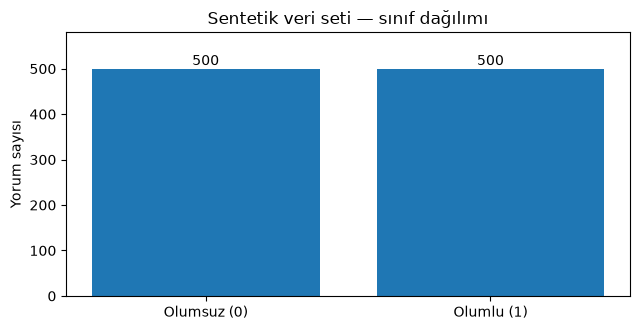

In [44]:
df = pd.read_csv(BASE_DIR / "film_yorumlari.csv", encoding="utf-8-sig")
zor = pd.read_csv(BASE_DIR / "zor_ornekler.csv", encoding="utf-8-sig")
assert set(df.columns) == {"yorum", "etiket", "temel_id"}
assert set(df["etiket"].unique()) == {0, 1}
assert df["yorum"].notna().all() and not df["yorum"].duplicated().any()
assert len(df) == 1000 and (df["etiket"].value_counts().sort_index() == 500).all()
assert len(zor) == 40 and set(zor['etiket'].unique()) == {0,1}
print("Veri kümesi:",df.shape, "| Bağımsız zor örnek:",zor.shape)
print("Sınıf dağılımı:",df["etiket"].value_counts().sort_index().to_dict())
print("Temel yorum grubu sayısı:",df["temel_id"].nunique())
display(df[['yorum','etiket']].head(8))
fig, ax = plt.subplots(figsize=(6.5,3.4))
counts = df['etiket'].value_counts().reindex([0,1])
ax.bar(['Olumsuz (0)','Olumlu (1)'],counts)
ax.set(ylabel='Yorum sayısı',title='Sentetik veri seti — sınıf dağılımı',ylim=(0,580))
for i, n in enumerate(counts): ax.text(i, n+8, str(n), ha='center')
fig.tight_layout()
fig.savefig(SONUCLAR/'sinif_dagilimi.png',dpi=140,bbox_inches='tight')
plt.show()

## 3. Ön işleme: Tokenization ve Stop Words — 

Cümleler Türkçe karakterlere uygun biçimde küçük harfe çevrilir, işaretler kaldırılır, sözcüklere ayrılır. `değil`, `hiç`, `ama`, `asla`, `çok` **silinmez**, çünkü olumsuzluk ve vurgu duygu yönünü değiştirebilir. Kök bulma/stemming kullanılmıyor; ders içinde anlatılmış olsa da doğru Türkçe kök bulma için burada tahminî kural eklemek istemiyoruz.

In [45]:
# Türkçe karakterlerde I/İ dönüşümüne dikkat ediyoruz.
DOLGU_SOZCUKLER = {'bir','ve','ile','için','ki','şu','bunu','bunlar','olarak','böyle','her','hem'}

def kucult_tr(metin):
    return str(metin).replace('I','ı').replace('İ','i').lower()

def tokenize(metin):
    kelimeler = re.findall(r"[a-zçğıöşü]+", kucult_tr(metin))
    return [k for k in kelimeler if k not in DOLGU_SOZCUKLER]

ornek = "Film gerçekten çok güzeldi! Hiç sıkılmadım."
print('Orijinal:', ornek)
print('Tokenlar:', tokenize(ornek))
print('Zor örnek:', tokenize('İyi değil, hiç beğenmedim!'))

Orijinal: Film gerçekten çok güzeldi! Hiç sıkılmadım.
Tokenlar: ['film', 'gerçekten', 'çok', 'güzeldi', 'hiç', 'sıkılmadım']
Zor örnek: ['iyi', 'değil', 'hiç', 'beğenmedim']


## 4. Eğitim–test ayrımı

 veri ikiye ayrılır. Burada önemli bir ek önlem alıyoruz: **aynı temel cümlenin varyasyonları birbirinin kopyası gibi kolay öğrenilebilir**, bu yüzden temel yorum kimliğine göre yaklaşık `%80 eğitim / %20 test` ayrımı yaparız. Her iki sınıfın temel yorumları eşit oranda ayrılır. `zor_ornekler.csv` ise hiçbir eğitim, Grid Search veya parametre seçim aşamasında kullanılmaz.

In [46]:
grup_etiketleri = df[['temel_id','etiket']].drop_duplicates().reset_index(drop=True)
train_ids, test_ids = train_test_split(
    grup_etiketleri['temel_id'], test_size=0.20, random_state=RANDOM_STATE,
    stratify=grup_etiketleri['etiket']
)
train_df = df[df['temel_id'].isin(set(train_ids))].copy().reset_index(drop=True)
test_df  = df[df['temel_id'].isin(set(test_ids))].copy().reset_index(drop=True)
assert set(train_df['temel_id']).isdisjoint(set(test_df['temel_id']))
assert len(train_df) + len(test_df) == len(df)
X_train, y_train = train_df['yorum'], train_df['etiket']
X_test,  y_test  = test_df['yorum'], test_df['etiket']
gruplar_train = train_df['temel_id']
print(f'Eğitim: {len(train_df)} yorum, {train_df.temel_id.nunique()} temel yorum')
print(f'Test:   {len(test_df)} yorum, {test_df.temel_id.nunique()} temel yorum')
print('Eğitim sınıf sayıları:',y_train.value_counts().sort_index().to_dict())
print('Test sınıf sayıları:',y_test.value_counts().sort_index().to_dict())
print('Ortak temel_id:',len(set(train_df.temel_id) & set(test_df.temel_id)))

Eğitim: 802 yorum, 128 temel yorum
Test:   198 yorum, 32 temel yorum
Eğitim sınıf sayıları: {0: 398, 1: 404}
Test sınıf sayıları: {0: 102, 1: 96}
Ortak temel_id: 0


## 5. Counting Vectors ve TF-IDF — 

**Counting Vector:** Sözlükte bulunan her sözcüğün sayısı bir vektör bileşenidir. Örnek `film:1, güzel:1, kötü:0` şeklindedir.

**TF-IDF :

\[
TF(t,d)=\frac{\mathrm{count}(t,d)}{\mathrm{len}(d)},\quad
IDF(t)=\log\left(\frac{D}{D(t)}\right),\quad TF\!\! -\!\! IDF=TF\times IDF
\]

Burada `D` doküman sayısı, `D(t)` kelimenin geçtiği doküman sayısıdır. Scikit-learn'ün `TfidfVectorizer` **varsayılan TF-IDF ayarı** ders slaytından küçük farklar taşır: IDF üzerinde düzeltme ve L2 normalizasyon kullanır. Bu çalışmada kütüphanenin seçimini açıkça belirtiyoruz; **aynı rakamların çıkmasını beklemiyoruz**.

Önemli kural: Vektörleştirme sözlüğü yalnızca **eğitim** verisinde öğrenilir (`Pipeline` eğitim sırasında `fit`). Böylece test verisinden bilgi sızmaz. Testte görülmemiş kelimeler hazır `CountVectorizer/TfidfVectorizer` içinde bilinmeyen sözcük olarak yok sayılır; ayrıca ayrı bir `<UNK>` boyutu eklenmez.

In [47]:
demo = ["Film harika ve güzel", "Film kötü ve sıkıcı"]
cv_demo = CountVectorizer(tokenizer=tokenize,token_pattern=None,lowercase=False)
sayim = cv_demo.fit_transform(demo)
print('Sözlük:',cv_demo.get_feature_names_out().tolist())
print('Counting vektörleri\n',sayim.toarray())
tf_demo = TfidfVectorizer(tokenizer=tokenize,token_pattern=None,lowercase=False)
tfidf_demo = tf_demo.fit_transform(demo)
print('Scikit-learn TF-IDF vektörleri\n',np.round(tfidf_demo.toarray(),3))

Sözlük: ['film', 'güzel', 'harika', 'kötü', 'sıkıcı']
Counting vektörleri
 [[1 1 1 0 0]
 [1 0 0 1 1]]
Scikit-learn TF-IDF vektörleri
 [[0.449 0.632 0.632 0.    0.   ]
 [0.449 0.    0.    0.632 0.632]]


## 6. İki temsil ile Decision Tree — 

Aynı algoritmayı iki farklı sözcük temsilinde deneriz:

- **Model A:** Counting Vectors + Decision Tree
- **Model B:** TF-IDF + Decision Tree

Her iki modelde `max_depth=5` ve `criterion='entropy'` sabit tutulur; ilk karşılaştırma model ayarlarını değiştirmeden yapılır. Karar ağacında entropi, sınıf ayrımında kullanılan ölçüttür. **Testi hiperparametre seçmek için kullanmayız.**

In [48]:
def vektorleyici_yap(tip):
    ortak = {'tokenizer':tokenize, 'token_pattern':None, 'lowercase':False}
    if tip == 'Counting': return CountVectorizer(**ortak)
    if tip == 'TF-IDF': return TfidfVectorizer(**ortak)
    raise ValueError('Bilinmeyen temsil')

def boru_hatti(tip, depth=5, criterion='entropy'):
    return Pipeline([
        ('vektor',vektorleyici_yap(tip)),
        ('agac',DecisionTreeClassifier(criterion=criterion,
                                   max_depth=depth,random_state=RANDOM_STATE))
    ])

sabit_modeller = {'Counting':boru_hatti('Counting'), 'TF-IDF':boru_hatti('TF-IDF')}
for adi, model in sabit_modeller.items():
    model.fit(X_train,y_train)
    print(f'{adi:8} | Train accuracy: {model.score(X_train,y_train):.3f} | Yaprak sayısı: {model.named_steps["agac"].get_n_leaves()}')

Counting | Train accuracy: 0.741 | Yaprak sayısı: 7
TF-IDF   | Train accuracy: 0.741 | Yaprak sayısı: 7


## 7. Başarı ölçütleri —

**Accuracy:** doğru tahmin / toplam tahmin.  
**Precision:** olumlu tahminlerin ne kadarı gerçekten olumlu.  
**Recall:** gerçekten olumlu yorumların ne kadarı bulundu.  
**F1:** precision ve recall'un harmonik ortalaması.  

Sonuçları karşılaştırırken sınıflardan birine aşırı ağırlık vermemek için **macro F1** de gösteriyoruz. Bu değerlendirme testte bir kez yapılan gözlemdir; parametre seçimi bir sonraki bölümde sadece eğitim katları üzerinde yapılacaktır.

,Temsil,Accuracy,Precision,Recall,F1,Macro-F1
0,Counting,0.692,0.619,0.948,0.749,0.675
1,TF-IDF,0.692,0.619,0.948,0.749,0.675


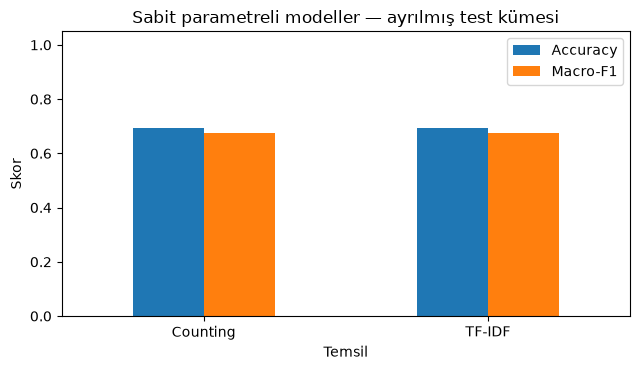

In [49]:
def metrikler(gercek,tahmin):
    return {
      'Accuracy': accuracy_score(gercek,tahmin),
      'Precision': precision_score(gercek,tahmin,zero_division=0),
      'Recall': recall_score(gercek,tahmin,zero_division=0),
      'F1': f1_score(gercek,tahmin,zero_division=0),
      'Macro-F1': f1_score(gercek,tahmin,average='macro',zero_division=0),
    }

ilk_sonuclar=[]
for adi, model in sabit_modeller.items():
    tahmin=model.predict(X_test)
    ilk_sonuclar.append({'Temsil':adi,**metrikler(y_test,tahmin)})
sonuc_tablosu=pd.DataFrame(ilk_sonuclar)
display(sonuc_tablosu.round(3))
sonuc_tablosu.to_csv(SONUCLAR/'ilk_karsilastirma.csv',index=False,encoding='utf-8-sig')
ax = sonuc_tablosu.set_index('Temsil')[['Accuracy','Macro-F1']].plot(kind='bar',figsize=(6.5,3.8),rot=0,ylim=(0,1.05))
ax.set(title='Sabit parametreli modeller — ayrılmış test kümesi',ylabel='Skor')
plt.tight_layout()
plt.savefig(SONUCLAR/'ilk_karsilastirma.png',dpi=140,bbox_inches='tight')
plt.show()

## 8. N-Fold Cross Validation —

Ders notlarındaki 5-katlı çapraz doğrulama mantığını uygularız: eğitim verisi beş katmana bölünür; her turda dört katman öğrenme, biri doğrulama içindir. Aynı temel yorumun varyasyonlarını katmanlara birlikte koymak için `GroupKFold` kullanıyoruz. Bu, yeni bir sınıflandırıcı değil, **dersin N-Fold doğrulamasındaki grup sızıntısını önleyen ayırma seçimi**dir. Test kümesi bu süreçte hiç kullanılmaz.

In [50]:
cv = GroupKFold(n_splits=5)
cv_sonuclari=[]
for adi in ['Counting','TF-IDF']:
    skorlar = cross_val_score(boru_hatti(adi), X_train,y_train,
                             groups=gruplar_train,cv=cv,scoring='f1_macro')
    cv_sonuclari.append({'Temsil':adi,'CV Macro-F1 ortalama':float(skorlar.mean()),
                         'Std':float(skorlar.std()),'Kat skorları':np.round(skorlar,3).tolist()})
cv_df=pd.DataFrame(cv_sonuclari)
display(cv_df)
cv_df.to_csv(SONUCLAR/'capraz_dogrulama.csv',index=False,encoding='utf-8-sig')

,Temsil,CV Macro-F1 ortalama,Std,Kat skorları
0,Counting,0.641460,0.077962,"[0.519, 0.741, 0.651, 0.598, 0.699]"
1,TF-IDF,0.683346,0.048031,"[0.706, 0.741, 0.673, 0.598, 0.699]"


## 9. Grid Search —

 hiperparametre deneme mantığıyla karar ağacının **criterion (gini/entropy)**, **max_depth (3/5/7/10)** ve **min_samples_leaf (1/3)** seçenekleri karşılaştırılır. Bu parametreler farklı karar ağaçları oluşturur. Her kombinasyon için beş doğrulama turu kullanılır.

**Önemli:** Parametreleri seçen Grid Search **yalnızca eğitim verisini** görür. Test skoru yalnızca seçilmiş modelin son değerlendirmesidir. `f1_macro` puanına göre en iyi kombinasyon alınır.

In [51]:
parametreler = {
    'agac__criterion':['gini','entropy'],
    'agac__max_depth':[3,5,7,10],
    'agac__min_samples_leaf':[1,3],
}
aramalar={}
for adi in ['Counting','TF-IDF']:
    gs=GridSearchCV(boru_hatti(adi),param_grid=parametreler,cv=cv,
                    scoring='f1_macro',n_jobs=1,refit=True,return_train_score=False)
    gs.fit(X_train,y_train,groups=gruplar_train)
    aramalar[adi]=gs
    print(adi, '| En iyi CV Macro-F1:', round(gs.best_score_,4), '| Ayarlar:',gs.best_params_)

Counting | En iyi CV Macro-F1: 0.8715 | Ayarlar: {'agac__criterion': 'entropy', 'agac__max_depth': 10, 'agac__min_samples_leaf': 1}
TF-IDF | En iyi CV Macro-F1: 0.8885 | Ayarlar: {'agac__criterion': 'entropy', 'agac__max_depth': 10, 'agac__min_samples_leaf': 1}


## 10. Model seçimi ve son test

Her iki temsilin Grid Search doğrulama skorları karşılaştırılır. **En iyi model test verisine bakılmadan** seçilir ve sonra ayrılmış test üzerinde raporlanır. Yanlış sınıflandırmalar özellikle önemlidir; sentetik yorumlar üzerinde yüksek başarı gerçek sitelerde aynı sonucu garanti etmez.

Seçilen temsil: TF-IDF
Seçilen parametreler: {'agac__criterion': 'entropy', 'agac__max_depth': 10, 'agac__min_samples_leaf': 1}
En iyi CV Macro-F1: 0.8885
Eğitim: {'Accuracy': 0.906, 'Precision': 0.843, 'Recall': 1.0, 'F1': 0.915, 'Macro-F1': 0.906}
Test: {'Accuracy': 0.869, 'Precision': 0.812, 'Recall': 0.948, 'F1': 0.875, 'Macro-F1': 0.868}

Test sınıflandırma raporu:
              precision    recall  f1-score   support

     Olumsuz       0.94      0.79      0.86       102
      Olumlu       0.81      0.95      0.88        96

    accuracy                           0.87       198
   macro avg       0.88      0.87      0.87       198
weighted avg       0.88      0.87      0.87       198



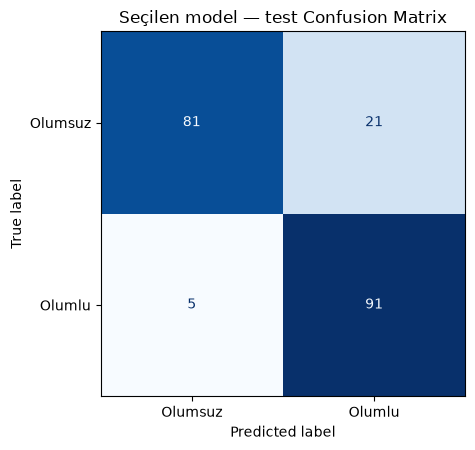

In [52]:
en_iyi_ad = max(aramalar,key=lambda k: aramalar[k].best_score_)
en_iyi_arama=aramalar[en_iyi_ad]
en_iyi_model=en_iyi_arama.best_estimator_
test_tahmin=en_iyi_model.predict(X_test)
test_metrikleri=metrikler(y_test,test_tahmin)
train_metrikleri=metrikler(y_train,en_iyi_model.predict(X_train))
print('Seçilen temsil:',en_iyi_ad)
print('Seçilen parametreler:',en_iyi_arama.best_params_)
print('En iyi CV Macro-F1:',round(en_iyi_arama.best_score_,4))
print('Eğitim:',{k:round(v,3) for k,v in train_metrikleri.items()})
print('Test:',{k:round(v,3) for k,v in test_metrikleri.items()})
print('\nTest sınıflandırma raporu:')
print(classification_report(y_test,test_tahmin,target_names=['Olumsuz','Olumlu'],zero_division=0))
fig,ax=plt.subplots(figsize=(5.5,4.6))
ConfusionMatrixDisplay.from_predictions(y_test,test_tahmin,labels=[0,1],
                                        display_labels=['Olumsuz','Olumlu'],ax=ax,
                                        colorbar=False,cmap='Blues')
ax.set_title('Seçilen model — test Confusion Matrix')
fig.tight_layout()
fig.savefig(SONUCLAR/'confusion_matrix.png',dpi=150,bbox_inches='tight')
plt.show()

## 11. Bağımsız ve zor yorumlar üzerinde kontrol

Bu bölümde **eğitim ve test havuzundan bağımsız**, ayrıca hazırlanmış 40 cümleyi inceliyoruz. Özellikle `kötü değil`, `başta güzel ama sonu kötü` gibi karmaşık örneklerde klasik sözcük temsili + karar ağacının hata yapması normaldir. **Bu örnekler modeli/ayarları yeniden seçmek için kullanılmaz**; dış geçerlik sınırlarını gözlemlemek içindir.

In [53]:
zor_tahmin=en_iyi_model.predict(zor['yorum'])
zor_metrikleri=metrikler(zor['etiket'],zor_tahmin)
zor_sonuc=zor.copy()
zor_sonuc['tahmin']=zor_tahmin
zor_sonuc['dogru_mu']=zor_sonuc['etiket'].eq(zor_sonuc['tahmin'])
print('Bağımsız zor örnek Accuracy:',round(zor_metrikleri['Accuracy'],3))
print('Bağımsız zor örnek Macro-F1:',round(zor_metrikleri['Macro-F1'],3))
print('Hatalı zor örnek sayısı:',int((~zor_sonuc['dogru_mu']).sum()),'/',len(zor_sonuc))
display(zor_sonuc[~zor_sonuc['dogru_mu']].head(15))
zor_sonuc.to_csv(SONUCLAR/'zor_ornek_tahminleri.csv',index=False,encoding='utf-8-sig')

Bağımsız zor örnek Accuracy: 0.425
Bağımsız zor örnek Macro-F1: 0.378
Hatalı zor örnek sayısı: 23 / 40


,yorum,etiket,tahmin,dogru_mu
0,"Kötü bir film bekliyordum, hiç de kötü değildi.",1,0,False
1,"Beni şaşırtan tarafı, hiç sıkılmamış olmam.",1,0,False
2,Başta sıkıcı görünse de hikâye giderek güzelle...,1,0,False
3,Bazı sahneleri beğenmedim ama genel olarak iyi...,1,0,False
11,Yavaş ilerledi ama hiç kopmadım.,1,0,False
12,"Müzikleri sevmedim, oyunculuklar ise şahane.",1,0,False
20,İyi olacağını umdum ama tam bir hayal kırıklığ...,0,1,False
21,Görüntüleri hoştu fakat hikâyesi berbat.,0,1,False
23,Bazı şakaları komikti ama toplamda kötüydü.,0,1,False
24,"Başlangıcı harikaydı, devamı tam bir fiyasko.",0,1,False


## 12. Rastgele yeni yorumlarda kullanım

Bu hücreler modelin kullanıcıdan gelen cümlelerde nasıl çalıştığını gösterir. Aşağıdaki örnekler yeni eğitim verisi oluşturmaz. Daha sonra `tahmin_et("...")` fonksiyonuna kendi filmin hakkındaki Türkçe yorumunu yazabilirsin.

In [58]:
def tahmin_et(yorum):
    sonuc=int(en_iyi_model.predict([yorum])[0])
    return 'Olumlu' if sonuc==1 else 'Olumsuz'

kullanici_ornekleri = [
    'Film çok kötüydü, oyunculukları beğenmedim.',
    'Çok sıkıcıydı, izlerken zaman kaybettim.',
    'Güzel bir film değildi.',
    'Güzel görüntülere rağmen senaryo çok kötüydü.',
]
for yorum in kullanici_ornekleri:
    print(f'{tahmin_et(yorum):8} | {yorum}')

Olumsuz  | Film çok kötüydü, oyunculukları beğenmedim.
Olumlu   | Çok sıkıcıydı, izlerken zaman kaybettim.
Olumlu   | Güzel bir film değildi.
Olumlu   | Güzel görüntülere rağmen senaryo çok kötüydü.


## 13. Karar ağacını görselleştirme — 

Ağacın ilk birkaç ayrımını çizeriz. Bu çizimdeki kutular, modelin hangi sözcüğe göre ve hangi sırayla ayrım yaptığını gösterir. Kutu içindeki değerler teknik sınıflandırıcı çıktılarıdır; onları semantik bir dil modeliyle karıştırmamak gerekir.

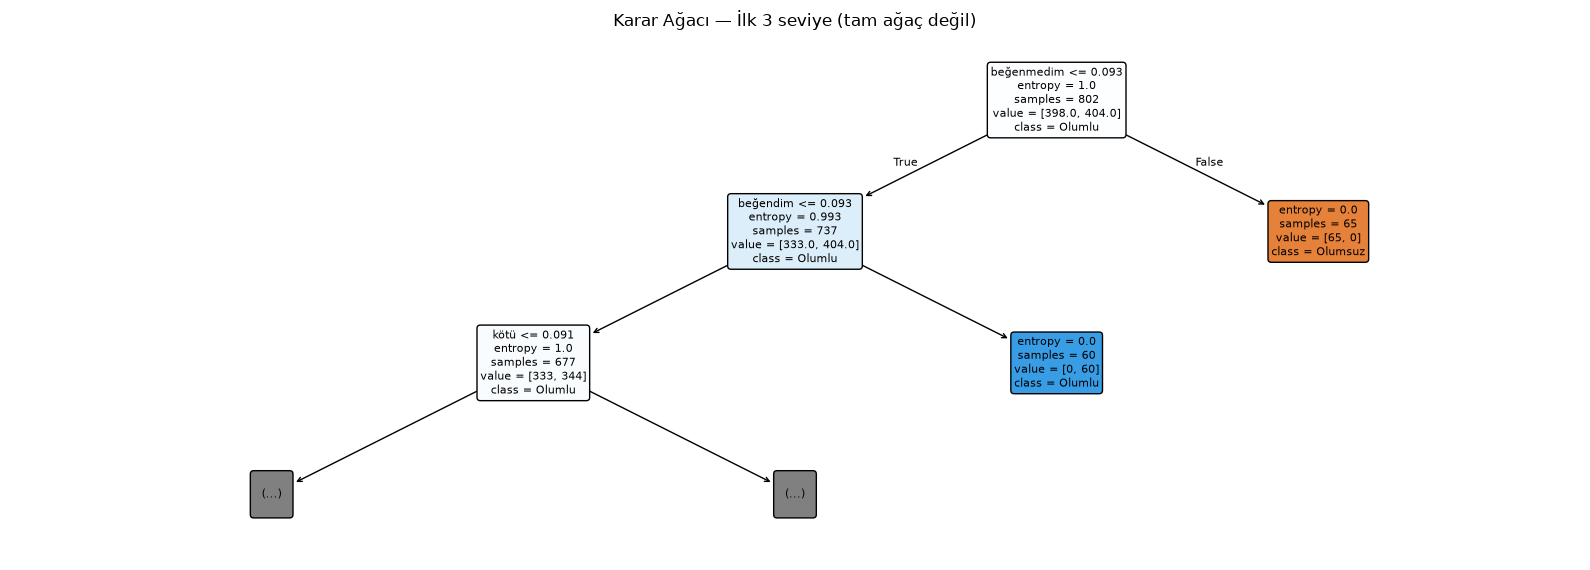

In [55]:
agac = en_iyi_model.named_steps['agac']
sozluk = en_iyi_model.named_steps['vektor'].get_feature_names_out()
fig,ax=plt.subplots(figsize=(16,5.8))
plot_tree(agac,feature_names=sozluk,class_names=['Olumsuz','Olumlu'],
          filled=True,rounded=True,max_depth=2,fontsize=8,ax=ax)
ax.set_title('Karar Ağacı — İlk 3 seviye (tam ağaç değil)')
fig.tight_layout()
fig.savefig(SONUCLAR/'karar_agaci.png',dpi=145,bbox_inches='tight')
plt.show()

## 14. Sonuçları kaydetme ve yorumlama

Aşağıdaki JSON dosyası seçilen modelin gerçekten çalıştırılmış ölçümlerini kaydeder. Bu dosya README'deki sayısal sonuçlarla karşılaştırılabilir.

### Yöntem ve etik sınırlamalar

- Eğitim/test havuzu **sentetik ve şablonlardan genişletilmiş** olduğundan metin çeşitliliği gerçekte olduğundan azdır. Aynı `temel_id` gruplarını ayrı tutmak önemli fakat tek başına yeterli değildir.
- Gerçek IMDb/Beyazperde yorumları, ironi, yazım hataları ve karma duygu içeren başka bir dağılımdır. Gerçek dünya performansı **ölçülmemiştir**.
- Karar ağaçları, duygunun bağlama göre değişimini ve negasyonu her zaman doğru anlayamaz.
- Veri seti belirli film adlarına, kişisel bilgilere, izleyici hesaplarına veya kazınmış web içeriğine dayanmaz.
- Sonuçların iyileştirilmesi için gelecekte **gerçek, izinli ve elle etiketli** veriyle test yapılması gerekir. Ancak burada dersin dışındaki modeller kullanılmadı.

In [56]:
rapor = {
  'veri_turu': 'özgün sentetik, şablonlardan üretilmiş, gerçek kullanıcı yorumu değil',
  'toplam_veri':int(len(df)),
  'egitim_sayisi':int(len(X_train)), 'test_sayisi':int(len(X_test)),
  'zor_ornek_sayisi':int(len(zor)),
  'secilen_temsil':en_iyi_ad,
  'parametreler':en_iyi_arama.best_params_,
  'en_iyi_cv_macro_f1':float(en_iyi_arama.best_score_),
  'train':train_metrikleri, 'test':test_metrikleri,
  'zor_ornekler':zor_metrikleri,
  'ilk_karsilastirma':sonuc_tablosu.to_dict(orient='records'),
  'cv_karsilastirma':cv_sonuclari,
  'sklearn_surumu':sklearn.__version__,
  'random_state':RANDOM_STATE
}
with (SONUCLAR/'rapor.json').open('w',encoding='utf-8') as f:
    json.dump(rapor,f,ensure_ascii=False,indent=2)
print('Rapor kaydedildi:',SONUCLAR/'rapor.json')
print('SONUÇ — Test Macro-F1:',round(test_metrikleri['Macro-F1'],3),
      '| Bağımsız zor örnek Macro-F1:',round(zor_metrikleri['Macro-F1'],3))
assert (SONUCLAR/'rapor.json').exists()
assert len(set(train_df['temel_id']) & set(test_df['temel_id'])) == 0
print('Veri sızıntısı için temel_id ayrımı kontrol edildi: BAŞARILI')

Rapor kaydedildi: c:\Users\mert_\Desktop\film_yorumlari_duygu_analizi\sonuclar\rapor.json
SONUÇ — Test Macro-F1: 0.868 | Bağımsız zor örnek Macro-F1: 0.378
Veri sızıntısı için temel_id ayrımı kontrol edildi: BAŞARILI
